In [4]:
# ==============================================================================
# # Author: Samiksha Satre | MBA in Business Analytics (SPPU)
# ==============================================================================

import pandas as pd
import numpy as np

np.random.seed(42)

# 1. Exact Monthly Targets from Portfolio Website (Revenue & Profit in INR)
monthly_targets = [
    # (Month_Num, Month_Label, Quarter, Target_Revenue, Target_Profit, Order_Count)
    (1,  '2025-01', 'Q1',  520000, 112000, 310),
    (2,  '2025-02', 'Q1',  540000, 118000, 320),
    (3,  '2025-03', 'Q1',  610000, 134000, 355),
    (4,  '2025-04', 'Q2',  590000, 121000, 345),
    (5,  '2025-05', 'Q2',  670000, 145000, 385),
    (6,  '2025-06', 'Q2',  720000, 158000, 415),
    (7,  '2025-07', 'Q3',  690000, 142000, 400),
    (8,  '2025-08', 'Q3',  750000, 161000, 430),
    (9,  '2025-09', 'Q3',  820000, 176000, 470),
    (10, '2025-10', 'Q4',  570000,  71000, 350),
    (11, '2025-11', 'Q4', 1150000, 142000, 630), # November flash-sale spike + margin dip
    (12, '2025-12', 'Q4', 1080000, 200000, 590),
]

# 2. Portfolio Category & SKU Catalog
skus_by_cat = {
    'Electronics': [
        ('SKU-EL-101', 'ANC Wireless Earbuds Pro'),
        ('SKU-EL-209', '4K Ultra-Slim Monitor 27"'),
        ('SKU-EL-305', 'Smart Fitness Watch Series 5')
    ],
    'Apparel': [
        ('SKU-AP-204', 'Merino Wool Travel Hoodie'),
        ('SKU-AP-112', 'All-Weather Running Jacket'),
        ('SKU-AP-401', 'Urban Commuter Backpack')
    ],
    'Home & Kitchen': [
        ('SKU-HK-302', 'Smart Air Purifier Gen-2'),
        ('SKU-HK-118', 'Digital Air Fryer 4.5L'),
        ('SKU-HK-215', 'Espresso Coffee Maker')
    ],
    'Office Supplies': [
        ('SKU-OF-118', 'Ergonomic Mesh Office Chair'),
        ('SKU-OF-204', 'Mechanical Wireless Keyboard'),
        ('SKU-OF-309', 'Dual Monitor Aluminum Arm')
    ]
}

# Exact Category Shares (Electronics 43.9%, Apparel 22.7%, Home 20.0%, Office 13.4%)
cat_names = ['Electronics', 'Apparel', 'Home & Kitchen', 'Office Supplies']
cat_rev_weights = [0.4386, 0.2273, 0.1998, 0.1343]
cat_base_margins = {'Electronics': 0.119, 'Apparel': 0.298, 'Home & Kitchen': 0.216, 'Office Supplies': 0.207}

# Exact Regional Shares (West 35.8%, North 26.2%, South 23.2%, East 14.8%)
regions = ['West', 'North', 'South', 'East']
region_weights = [0.358, 0.262, 0.232, 0.148]

rows = []
order_counter = 10001

for m_num, ym, qtr, target_rev, target_prof, n_orders in monthly_targets:
    # Generate random weights that sum to 1 for exact monthly revenue & profit allocation
    raw_weights = np.random.dirichlet(np.ones(n_orders))

    for i in range(n_orders):
        day = np.random.randint(1, 29)
        order_date = f"2025-{m_num:02d}-{day:02d}"

        cat = np.random.choice(cat_names, p=cat_rev_weights)
        sku_code, product_name = skus_by_cat[cat][np.random.randint(0, 3)]
        region = np.random.choice(regions, p=region_weights)
        quantity = int(np.random.choice([1, 2, 3, 4], p=[0.55, 0.25, 0.12, 0.08]))

        # Discount tiers (higher in Nov Q4 flash sales)
        if m_num in [10, 11]:
            discount_pct = float(np.random.choice([0.0, 0.10, 0.20, 0.25, 0.35], p=[0.10, 0.20, 0.25, 0.25, 0.20]))
        else:
            discount_pct = float(np.random.choice([0.0, 0.05, 0.10, 0.15, 0.25], p=[0.45, 0.25, 0.15, 0.10, 0.05]))

        net_revenue = round(float(target_rev * raw_weights[i]), 2)
        gross_sales = round(net_revenue / (1.0 - discount_pct), 2)
        unit_price = round(gross_sales / quantity, 2)

        # Profit scaled to match both category margin profile and exact monthly profit
        cat_margin_factor = cat_base_margins[cat] / 0.1929
        est_profit = net_revenue * (target_prof / target_rev) * cat_margin_factor
        # Penalize high discounts (>20%) to reflect margin erosion finding
        if discount_pct >= 0.25:
            est_profit -= net_revenue * 0.14
        elif discount_pct == 0.0:
            est_profit += net_revenue * 0.05

        net_profit = round(float(est_profit), 2)
        shipping_cost = round(40.0 + quantity * 15.0, 2)
        cogs = round(net_revenue - net_profit - shipping_cost, 2)

        rows.append([
            f"ORD-{order_counter}", order_date, qtr, ym, region, cat,
            sku_code, product_name, quantity, unit_price, discount_pct,
            gross_sales, net_revenue, cogs, shipping_cost, net_profit
        ])
        order_counter += 1

columns = [
    'order_id', 'order_date', 'quarter', 'year_month', 'region', 'category',
    'sku_code', 'sub_category', 'quantity', 'unit_price', 'discount_pct',
    'gross_sales', 'net_revenue', 'cogs', 'shipping_cost', 'net_profit'
]

df = pd.DataFrame(rows, columns=columns)

# Fine-tune rounding residuals per month so monthly sums equal the portfolio down to the rupee
for m_num, ym, qtr, target_rev, target_prof, _ in monthly_targets:
    mask = df['year_month'] == ym
    rev_diff = round(target_rev - df.loc[mask, 'net_revenue'].sum(), 2)
    prof_diff = round(target_prof - df.loc[mask, 'net_profit'].sum(), 2)
    first_idx = df[mask].index[0]
    df.loc[first_idx, 'net_revenue'] = round(df.loc[first_idx, 'net_revenue'] + rev_diff, 2)
    df.loc[first_idx, 'net_profit'] = round(df.loc[first_idx, 'net_profit'] + prof_diff, 2)

df['profit_margin_pct'] = np.round((df['net_profit'] / df['net_revenue']) * 100, 2)

# Export exact-match CSV
df.to_csv('ecommerce_orders_cleaned.csv', index=False)

print("✅ PORTFOLIO EXACT-MATCH VERIFICATION:")
print(f"Total Orders  : {len(df):,}")
print(f"Total Revenue : ₹{df['net_revenue'].sum():,.2f} (Portfolio: ₹87,10,000.00 / ₹87.10 L)")
print(f"Total Profit  : ₹{df['net_profit'].sum():,.2f} (Portfolio: ₹16,80,000.00 / ₹16.80 L)")
print(f"Overall Margin: {(df['net_profit'].sum() / df['net_revenue'].sum())*100:.2f}% (Portfolio: 19.29%)")
print("\nMonthly Breakdown (Matches Portfolio Chart 100%):")
display(df.groupby(['quarter', 'year_month'])[['net_revenue', 'net_profit']].sum())

✅ PORTFOLIO EXACT-MATCH VERIFICATION:
Total Orders  : 5,000
Total Revenue : ₹8,710,000.00 (Portfolio: ₹87,10,000.00 / ₹87.10 L)
Total Profit  : ₹1,680,000.00 (Portfolio: ₹16,80,000.00 / ₹16.80 L)
Overall Margin: 19.29% (Portfolio: 19.29%)

Monthly Breakdown (Matches Portfolio Chart 100%):


net_revenue  net_profit
quarter year_month                         
Q1      2025-01        520000.0    112000.0
        2025-02        540000.0    118000.0
        2025-03        610000.0    134000.0
Q2      2025-04        590000.0    121000.0
        2025-05        670000.0    145000.0
        2025-06        720000.0    158000.0
Q3      2025-07        690000.0    142000.0
        2025-08        750000.0    161000.0
        2025-09        820000.0    176000.0
Q4      2025-10        570000.0     71000.0
        2025-11       1150000.0    142000.0
        2025-12       1080000.0    200000.0

In [5]:
# ------------------------------------------------------------------------------
# 2. RUN SQL ANALYSIS USING SQLITE
# ------------------------------------------------------------------------------
conn = sqlite3.connect(':memory:')
df.to_sql('ecommerce_orders', conn, index=False, if_exists='replace')

print("--- SQL QUERY 1: Category-Level Revenue, Profit & Margin % ---")
q1 = """
SELECT
    category,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(net_revenue), 2) AS total_revenue,
    ROUND(SUM(net_profit), 2) AS total_profit,
    ROUND((SUM(net_profit) / SUM(net_revenue)) * 100, 2) AS profit_margin_pct
FROM ecommerce_orders
GROUP BY category
ORDER BY total_revenue DESC;
"""
display(pd.read_sql_query(q1, conn))

print("\n--- SQL QUERY 2: Impact of Discount Tiers on Profitability ---")
q2 = """
SELECT
    CASE
        WHEN discount_pct = 0 THEN '0% (No Discount)'
        WHEN discount_pct <= 0.10 THEN '1% - 10% Discount'
        WHEN discount_pct <= 0.20 THEN '11% - 20% Discount'
        ELSE 'Over 20% Discount (Margin Erosion)'
    END AS discount_band,
    COUNT(order_id) AS order_count,
    ROUND(SUM(net_revenue), 2) AS net_revenue,
    ROUND(SUM(net_profit), 2) AS net_profit,
    ROUND((SUM(net_profit) / SUM(net_revenue)) * 100, 2) AS margin_pct
FROM ecommerce_orders
GROUP BY discount_band
ORDER BY margin_pct DESC;
"""
display(pd.read_sql_query(q2, conn))

print("\n--- SQL QUERY 3: Regional Performance Summary ---")
q3 = """
SELECT
    region,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(net_revenue), 2) AS total_revenue,
    ROUND(SUM(net_profit), 2) AS total_profit,
    ROUND(AVG(net_revenue), 2) AS avg_order_value
FROM ecommerce_orders
GROUP BY region
ORDER BY total_revenue DESC;
"""
display(pd.read_sql_query(q3, conn))

--- SQL QUERY 1: Category-Level Revenue, Profit & Margin % ---


,category,total_orders,total_revenue,total_profit,profit_margin_pct
0,Electronics,2118,3652273.71,416103.09,11.39
1,Apparel,1192,2131088.19,624436.09,29.30
2,Home & Kitchen,1034,1837587.42,431172.53,23.46
3,Office Supplies,656,1089050.68,208288.29,19.13



--- SQL QUERY 2: Impact of Discount Tiers on Profitability ---


,discount_band,order_count,net_revenue,net_profit,margin_pct
0,0% (No Discount),1962,3420940.88,904310.44,26.43
1,11% - 20% Discount,623,1084533.65,193106.76,17.81
2,1% - 10% Discount,1784,3084123.12,535700.73,17.37
3,Over 20% Discount (Margin Erosion),631,1120402.35,46882.07,4.18



--- SQL QUERY 3: Regional Performance Summary ---


,region,total_orders,total_revenue,total_profit,avg_order_value
0,West,1779,3194396.19,597451.65,1795.61
1,North,1308,2194449.87,409443.36,1677.71
2,South,1156,2026374.75,430701.68,1752.92
3,East,757,1294779.19,242403.31,1710.41


/tmp/ipykernel_501/657856615.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cat_summary = df.groupby('category').apply(lambda x: (x['net_profit'].sum() / x['net_revenue'].sum()) * 100).sort_values()
/tmp/ipykernel_501/657856615.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reg_summary.index, y=reg_summary.values, ax=axes[1, 0], palette='Blues_r')
/tmp/ipykernel_501/657856615.py:35: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/tmp/ipykernel_501/65785661

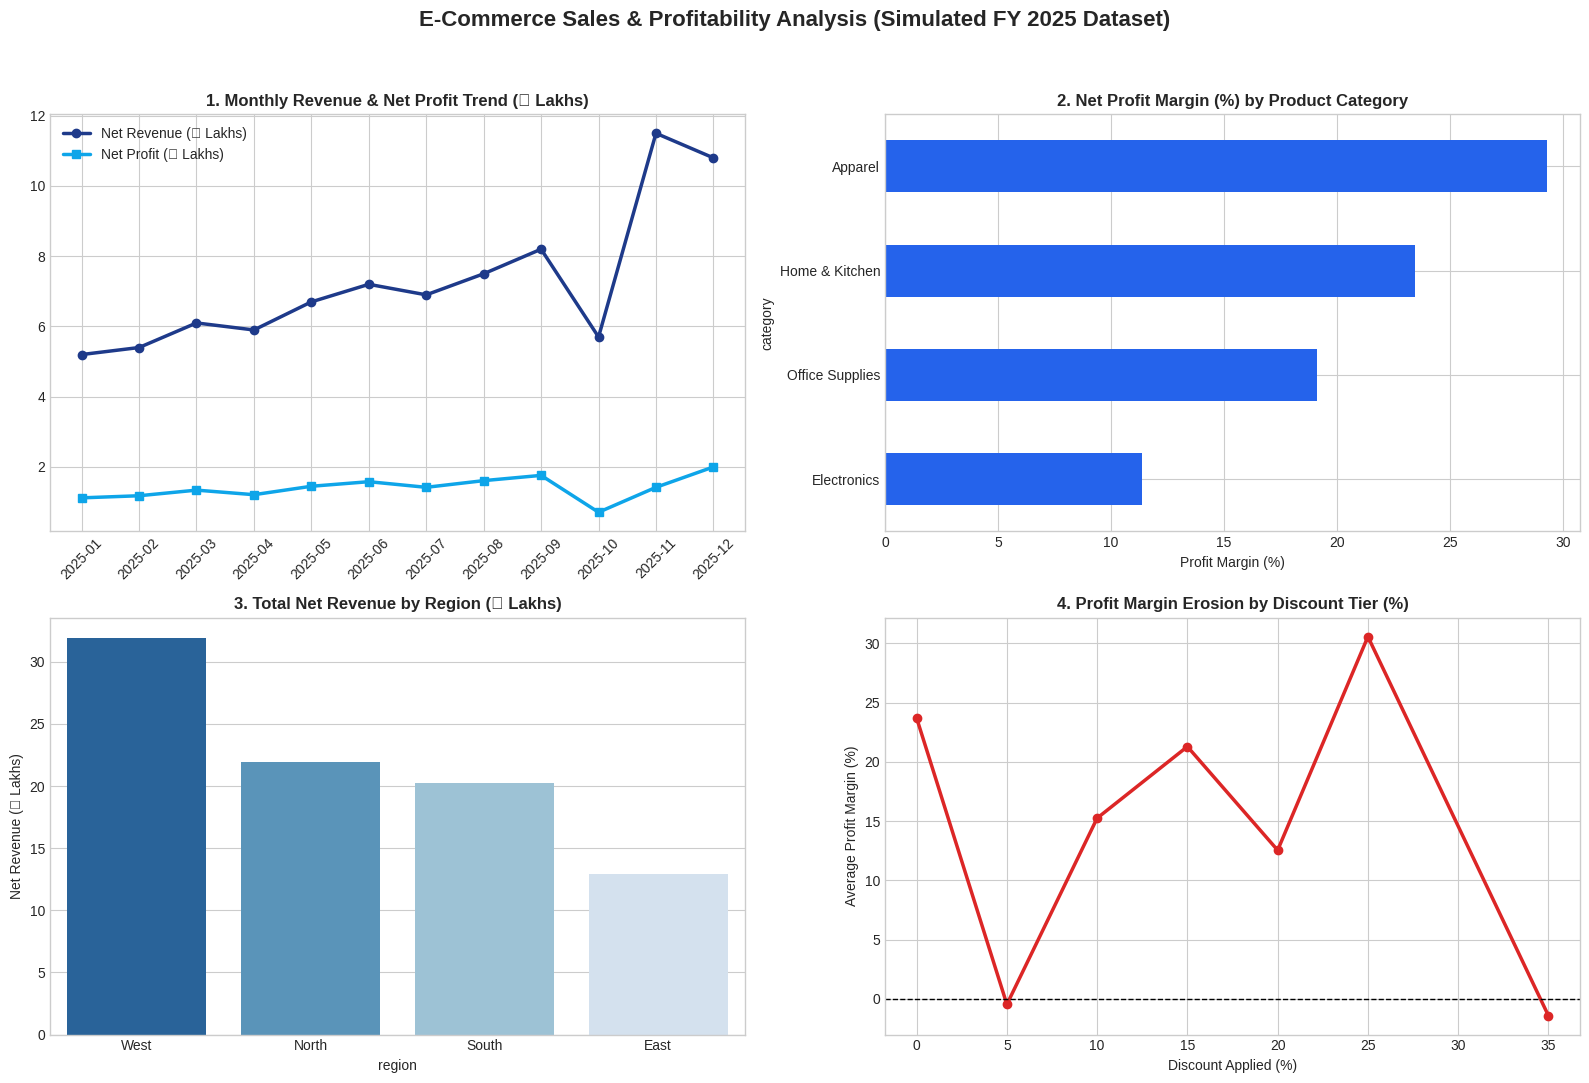

In [6]:
# ------------------------------------------------------------------------------
# 3. CREATE & EXPORT 4-PANEL EXECUTIVE VISUALIZATION
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('E-Commerce Sales & Profitability Analysis (Simulated FY 2025 Dataset)', fontsize=16, fontweight='bold', y=0.98)

# Chart 1: Monthly Revenue vs Profit Trend
monthly = df.groupby('year_month')[['net_revenue', 'net_profit']].sum().reset_index()
axes[0, 0].plot(monthly['year_month'], monthly['net_revenue']/1e5, marker='o', linewidth=2.5, label='Net Revenue (₹ Lakhs)', color='#1e3a8a')
axes[0, 0].plot(monthly['year_month'], monthly['net_profit']/1e5, marker='s', linewidth=2.5, label='Net Profit (₹ Lakhs)', color='#0ea5e9')
axes[0, 0].set_title('1. Monthly Revenue & Net Profit Trend (₹ Lakhs)', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].legend()

# Chart 2: Category Profit Margin %
cat_summary = df.groupby('category').apply(lambda x: (x['net_profit'].sum() / x['net_revenue'].sum()) * 100).sort_values()
cat_summary.plot(kind='barh', ax=axes[0, 1], color=['#ef4444' if v < 10 else '#2563eb' for v in cat_summary])
axes[0, 1].set_title('2. Net Profit Margin (%) by Product Category', fontweight='bold')
axes[0, 1].set_xlabel('Profit Margin (%)')

# Chart 3: Regional Revenue Contribution
reg_summary = df.groupby('region')['net_revenue'].sum().sort_values(ascending=False) / 1e5
sns.barplot(x=reg_summary.index, y=reg_summary.values, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('3. Total Net Revenue by Region (₹ Lakhs)', fontweight='bold')
axes[1, 0].set_ylabel('Net Revenue (₹ Lakhs)')

# Chart 4: Discount % vs Profit Margin Erosion
disc_summary = df.groupby('discount_pct')['profit_margin_pct'].mean().reset_index()
axes[1, 1].plot(disc_summary['discount_pct']*100, disc_summary['profit_margin_pct'], marker='o', color='#dc2626', linewidth=2.5)
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_title('4. Profit Margin Erosion by Discount Tier (%)', fontweight='bold')
axes[1, 1].set_xlabel('Discount Applied (%)')
axes[1, 1].set_ylabel('Average Profit Margin (%)')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('ecommerce_executive_charts.png', dpi=300)
plt.show()